# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [4]:
%pylab inline
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


D:\ML\env\Lib\site-packages\IPython\core\magics\pylab.py:166: UserWarning: pylab import has clobbered these variables: ['plt']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [5]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [13]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np
import matplotlib.pyplot as plt

Ridge:  0
Lasso:  7


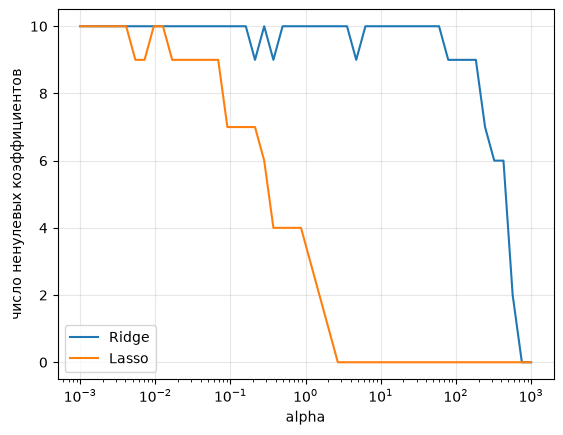

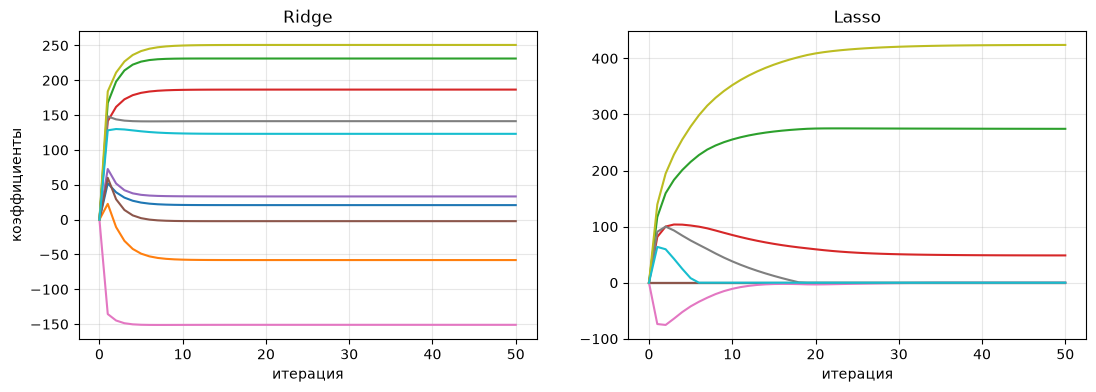

In [35]:
alphas = np.logspace(-3, 3, 50)
EPS = 1

ridge = Ridge().fit(X_train, y_train)
lasso = Lasso().fit(X_train, y_train)

print("Ridge: ", np.sum(abs(ridge.coef_) < EPS))
print("Lasso: ", np.sum(abs(lasso.coef_) < EPS))

for Model in (Ridge, Lasso):
    plt.semilogx(alphas, [np.sum(abs(Model(alpha=a).fit(X_train, y_train).coef_) > EPS) for a in alphas], label=Model.__name__)
plt.xlabel("alpha"); plt.ylabel("число ненулевых коэффициентов"); plt.legend(); plt.grid(alpha=0.3); plt.show()

def coef_path(penalty, alpha=1, n_iter=50):
    n = len(y_train)
    Xc, yc = X_train - X_train.mean(0), y_train - y_train.mean()
    L = np.linalg.eigvalsh(Xc.T @ Xc / n).max()
    lr = 1 / (L + alpha / n) if penalty == "l2" else 1 / L
    w, path = np.zeros(Xc.shape[1]), []
    path.append(w)
    for _ in range(n_iter):
        g = Xc.T @ (Xc @ w - yc) / n
        if penalty == "l2":
            w = w - lr * (g + alpha / n * w)
        else:
            z = w - lr * g
            w = np.sign(z) * np.maximum(abs(z) - lr * alpha, 0)
        path.append(w)
    return np.array(path)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, pen, title in [(axes[0], "l2", "Ridge"), (axes[1], "l1", "Lasso")]:
    ax.plot(coef_path(pen)); ax.set_title(title); ax.set_xlabel("итерация"); ax.grid(alpha=0.3)
axes[0].set_ylabel("коэффициенты")
plt.show()


Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [27]:
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [30]:
def metrics(y, p):
    return {"RMSE": mean_squared_error(y, p) ** 0.5, "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

ridge = Ridge().fit(X_train, y_train)
print("train:", metrics(y_train, ridge.predict(X_train)))
print("test: ", metrics(y_test, ridge.predict(X_test)))

train: {'RMSE': 58.32713753879843, 'MAE': 48.415547518370865, 'R2': 0.45095857829505925}
test:  {'RMSE': 58.30429511391227, 'MAE': 49.60275080965191, 'R2': 0.3599020220009461}


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

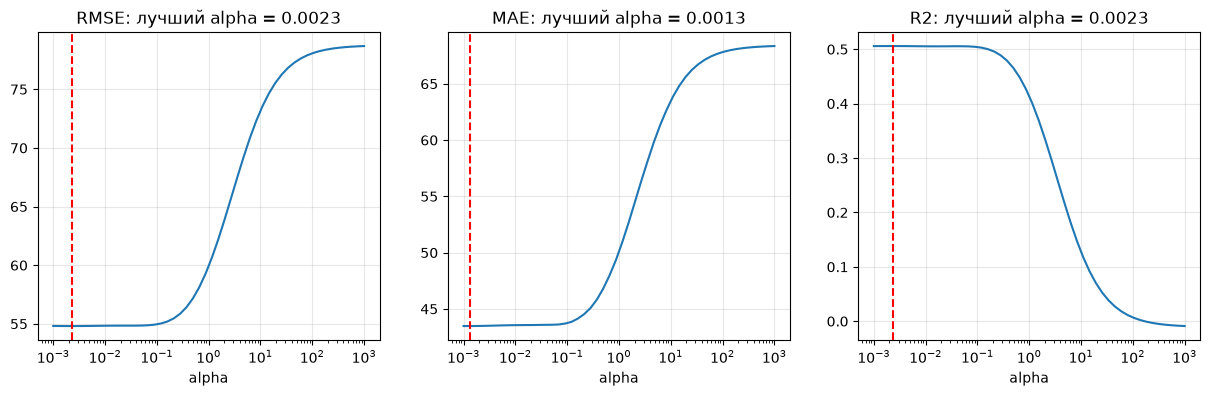

alpha=1: {'RMSE': 58.30429511391227, 'MAE': 49.60275080965191, 'R2': 0.3599020220009461}
RMSE, alpha=0.0023: {'RMSE': 55.81246302530944, 'MAE': 47.11537484494698, 'R2': 0.4134463603936328}
MAE, alpha=0.0013: {'RMSE': 55.843703404442635, 'MAE': 47.1441356059609, 'R2': 0.412789543422754}
R2, alpha=0.0023: {'RMSE': 55.81246302530944, 'MAE': 47.11537484494698, 'R2': 0.4134463603936328}


In [31]:
scorings = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}
best = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, sc) in zip(axes, scorings.items()):
    scores = np.array([cross_val_score(Ridge(alpha=a), X_train, y_train, cv=5, scoring=sc).mean() for a in alphas])
    best[name] = alphas[scores.argmax()] 
    ax.semilogx(alphas, scores if name == "R2" else -scores)
    ax.axvline(best[name], color="r", ls="--")
    ax.set_title(f"{name}: лучший alpha = {best[name]:.4f}"); ax.set_xlabel("alpha"); ax.grid(alpha=0.3)
plt.show()

print("alpha=1:", metrics(y_test, Ridge().fit(X_train, y_train).predict(X_test)))
for name, a in best.items():
    print(f"{name}, alpha={a:.4f}:", metrics(y_test, Ridge(alpha=a).fit(X_train, y_train).predict(X_test)))

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

In [ ]:
# code here

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [ ]:
# code here

__Задание 3.__ Отчёт

**(2 балла)**

In [ ]:
# code here